In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign

Dataset URL: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
License(s): CC0-1.0
100% 612M/612M [00:36<00:00, 17.6MB/s]



In [3]:
ls

drive/  gtsrb-german-traffic-sign.zip  sample_data/


In [4]:
import os

print(os.path.exists("/content/gtsrb-german-traffic-sign.zip"))

True


## **phase 3 (RNN , GRU , LSTM , Transformer )**

## **Imports**

In [5]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    Reshape,
    SimpleRNN,
    GRU,
    LSTM,
    Conv2D,
    MaxPooling2D,
    Flatten,
    TimeDistributed,
    BatchNormalization
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

### DATASET

In [6]:
import tensorflow as tf
import zipfile
import os

IMG_SIZE = (32, 32)
BATCH_SIZE = 32

zip_path = "/content/gtsrb-german-traffic-sign.zip"
extract_path = "/content/data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted successfully!")

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{extract_path}/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.3,
    subset="training",
    seed=123
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    f"{extract_path}/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.3,
    subset="validation",
    seed=123
)

num_classes = len(train_ds.class_names)
print("Number of classes:", num_classes)

val_batches = tf.data.experimental.cardinality(temp_ds).numpy()
val_ds = temp_ds.take(val_batches // 2)
test_ds = temp_ds.skip(val_batches // 2)

print("Dataset ready!")

Extracted successfully!
Found 39209 files belonging to 43 classes.
Using 27447 files for training.
Found 39209 files belonging to 43 classes.
Using 11762 files for validation.
Number of classes: 43
Dataset ready!


### Early sopping

In [7]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='best_model.keras',
    save_best_only=True,
    monitor='val_accuracy'
)

In [8]:
y_train = np.concatenate([
    y.numpy() for x, y in train_ds
])
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(class_weights))

print(class_weights)

{0: np.float64(4.763450190905935), 1: np.float64(0.42076620011957505), 2: np.float64(0.459540911145713), 3: np.float64(0.6915518153644586), 4: np.float64(0.4383944543828265), 5: np.float64(0.4244031420089065), 6: np.float64(1.156344792719919), 7: np.float64(1.4707426856714179), 8: np.float64(2.1347903865598505), 9: np.float64(0.82044000717403), 10: np.float64(0.7662692984170413), 11: np.float64(4.763450190905935), 12: np.float64(0.40682111254391035), 13: np.float64(2.5737996999249813), 14: np.float64(2.8752357008170963), 15: np.float64(2.417811839323467), 16: np.float64(1.7730620155038759), 17: np.float64(3.307265935654898), 18: np.float64(0.61257420881132), 19: np.float64(1.5161575429486824), 20: np.float64(3.732762137902897), 21: np.float64(1.666585706478839), 22: np.float64(3.395225136071252), 23: np.float64(0.6421552571241402), 24: np.float64(1.9640071556350627), 25: np.float64(1.1459646778840131), 26: np.float64(3.6896088183895683), 27: np.float64(1.355206636053918), 28: np.float6

In [9]:
def preprocess(image, label, augment=False):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

In [10]:
train_ds = train_ds.map(
    lambda x, y: preprocess(x, y),
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: preprocess(x, y),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    lambda x, y: preprocess(x, y),
    num_parallel_calls=tf.data.AUTOTUNE
)

## Build the Models

### Hybrid model using CNN as feature extraction (CNN + LSTM)

In [ ]:
def build_model(rnn_type='GRU'):

    model = Sequential()

    # CNN Backbone
    model.add(Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)))
    model.add(BatchNormalization())
    model.add(MaxPooling2D())

    model.add(Conv2D(64, (3,3), activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D())

    model.add(Conv2D(128, (3,3), activation='relu'))
    model.add(BatchNormalization())

    # Convert feature map to sequence
    model.add(Reshape((-1, 128)))

    # Sequence model
    if rnn_type == 'RNN':
        model.add(SimpleRNN(
            64,
            dropout=0.3,
            recurrent_dropout=0.3
        ))

    elif rnn_type == 'GRU':
        model.add(GRU(128))

    elif rnn_type == 'LSTM':
        model.add(LSTM(128))

    # Classification head
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.5))

    model.add(Dense(43, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

### Plot function

In [ ]:
def plot_his(history , name ):

    plt.figure(figsize=(8,5))
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(f"{name} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(['Train', 'Validation'])
    plt.show()

    plt.figure(figsize=(8,5))
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f"{name} loss")
    plt.xlabel("Epoch")
    plt.ylabel("loss")
    plt.legend(['Train', 'Validation'])
    plt.show()

### Train function

In [14]:
results = {}
def train(model , name ):

    print(f"\nTraining {name}\n")

    start = time.time()
    history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=[early_stop, checkpoint]
    )
    end = time.time()

    total_t = end - start

    loss, acc = model.evaluate(test_ds, verbose=0)

    print(f"\n{name} Accuracy: {acc:.4f}")
    print(f"{name} Loss: {loss:.4f}")
    print(f"{name} Training Time: {total_t:.2f} sec")

    y_pred = []
    y_true = []

    for images, labels in test_ds:

        preds = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    print("\nClassification Report:\n")
    print(classification_report(y_true, y_pred))

    # confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, cmap='Blues')
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    plot_his(history=history , name=name)
    results[name] = {
        "Accuracy": acc,
        "Loss": loss,
        "Training Time": total_t
    }

    return history

### Build the models

In [ ]:
rnn_model = build_model("RNN")
gru_model = build_model("GRU")
lstm_model = build_model("LSTM")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### train the models


Training Simple RNN

Epoch 1/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 87s 95ms/step - accuracy: 0.5111 - loss: 1.5764 - val_accuracy: 0.8003 - val_loss: 0.5955
Epoch 2/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 75s 88ms/step - accuracy: 0.8367 - loss: 0.3910 - val_accuracy: 0.9154 - val_loss: 0.2475
Epoch 3/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 75s 87ms/step - accuracy: 0.9067 - loss: 0.2292 - val_accuracy: 0.9581 - val_loss: 0.1401
Epoch 4/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 74s 86ms/step - accuracy: 0.9353 - loss: 0.1729 - val_accuracy: 0.9616 - val_loss: 0.1324
Epoch 5/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 82s 86ms/step - accuracy: 0.9470 - loss: 0.1380 - val_accuracy: 0.9667 - val_loss: 0.1076
Epoch 6/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 75s 88ms/step - accuracy: 0.9556 - loss: 0.1169 - val_accuracy: 0.9730 - val_loss: 0.0939
Epoch 7/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 75s 87ms/step - accuracy: 0.9606 - loss: 0.1003 - val_accuracy: 0.9671 - val_loss: 0.1119
Epoch 8/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 74s 86ms/step - accuracy: 0.

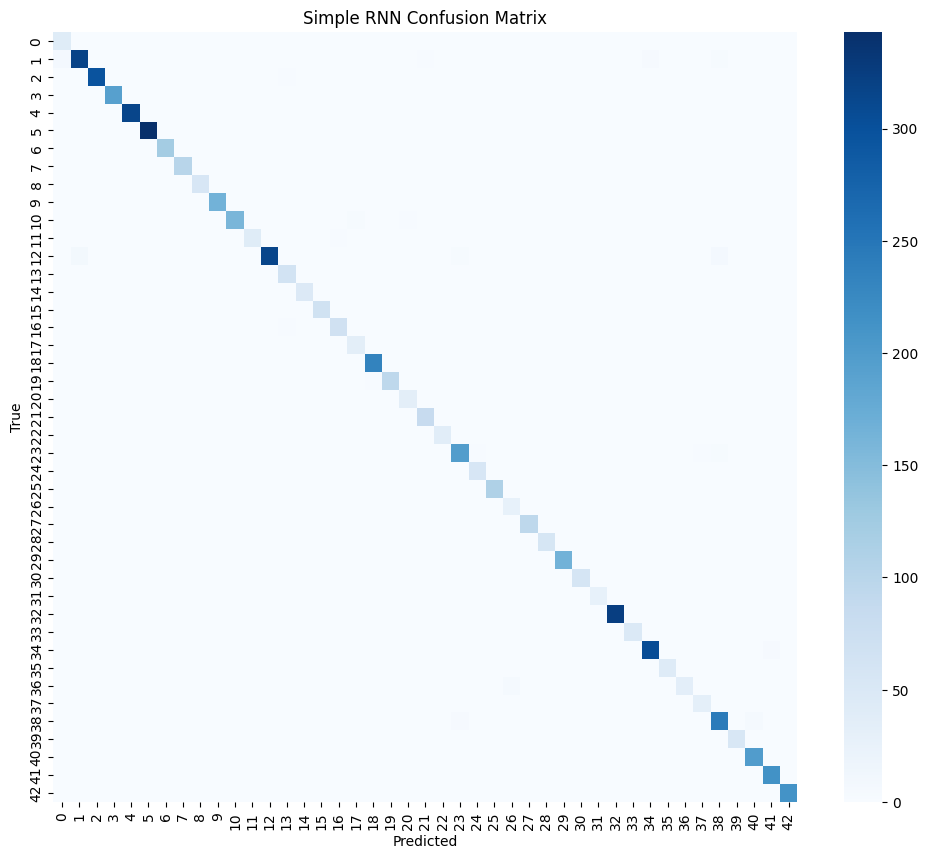

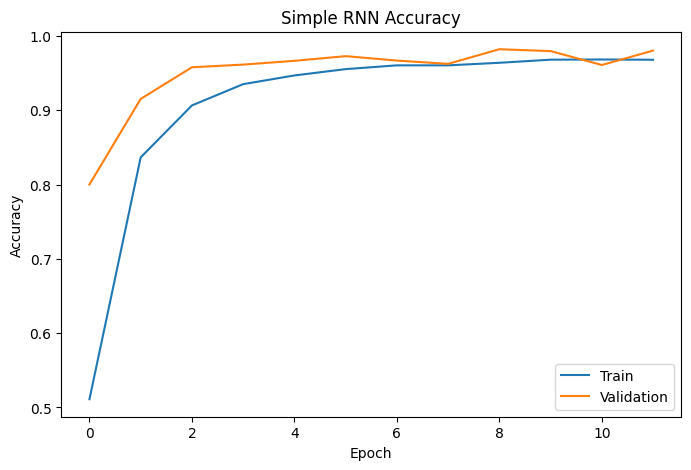

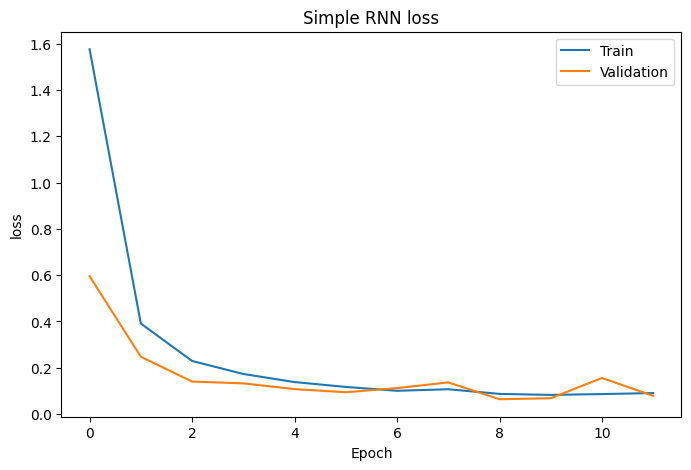

In [ ]:
train(rnn_model, "Simple RNN")



Training GRU

Epoch 1/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 96s 106ms/step - accuracy: 0.7042 - loss: 0.9380 - val_accuracy: 0.8957 - val_loss: 0.3310
Epoch 2/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 142s 106ms/step - accuracy: 0.9538 - loss: 0.1289 - val_accuracy: 0.9642 - val_loss: 0.1101
Epoch 3/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 91s 106ms/step - accuracy: 0.9679 - loss: 0.0899 - val_accuracy: 0.9346 - val_loss: 0.2418

GRU Accuracy: 0.9004
GRU Loss: 0.3220
GRU Training Time: 329.04 sec

Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.93      0.88        43
           1       0.90      0.87      0.89       338
           2       1.00      0.91      0.95       301
           3       0.97      0.89      0.93       204
           4       0.98      0.96      0.97       312
           5       0.98      0.96      0.97       341
           6       1.00      0.99      1.00       121
           7       0.89      0.99      0.94       103
          

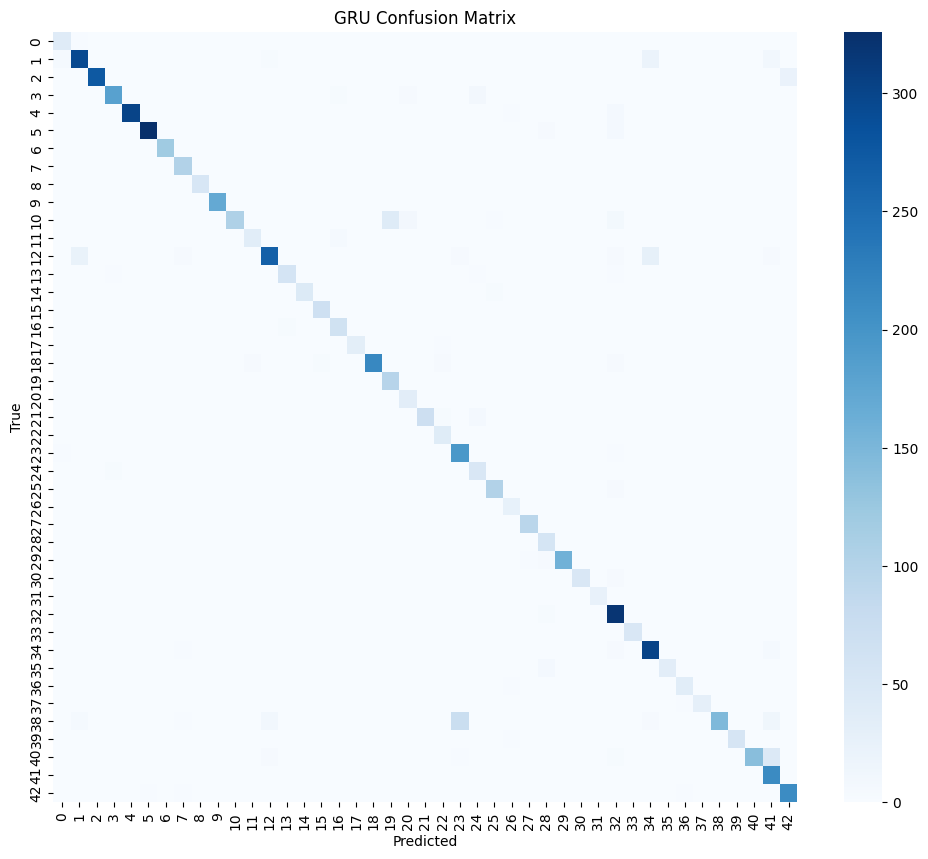

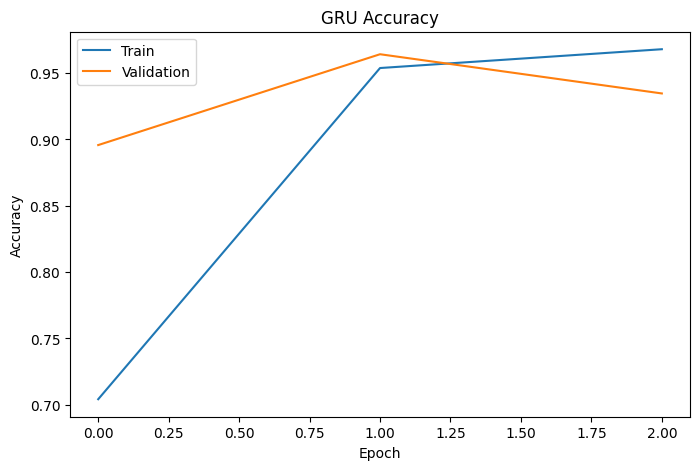

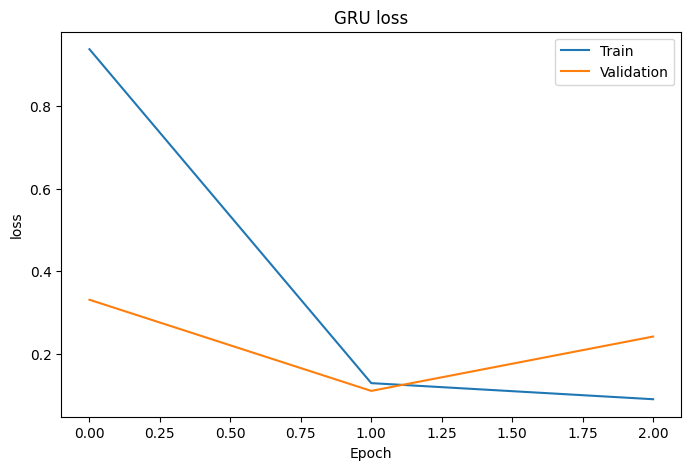

In [ ]:
train(gru_model, "GRU")



Training LSTM

Epoch 1/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 101s 112ms/step - accuracy: 0.6913 - loss: 0.9956 - val_accuracy: 0.9304 - val_loss: 0.2309
Epoch 2/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 100s 116ms/step - accuracy: 0.9555 - loss: 0.1258 - val_accuracy: 0.9472 - val_loss: 0.1809
Epoch 3/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 95s 111ms/step - accuracy: 0.9777 - loss: 0.0578 - val_accuracy: 0.9823 - val_loss: 0.0548
Epoch 4/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 142s 111ms/step - accuracy: 0.9795 - loss: 0.0576 - val_accuracy: 0.9407 - val_loss: 0.1937
Epoch 5/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 102s 118ms/step - accuracy: 0.9840 - loss: 0.0485 - val_accuracy: 0.9871 - val_loss: 0.0436
Epoch 6/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 96s 112ms/step - accuracy: 0.9899 - loss: 0.0270 - val_accuracy: 0.9146 - val_loss: 0.3136
Epoch 7/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 96s 112ms/step - accuracy: 0.9813 - loss: 0.0530 - val_accuracy: 0.8740 - val_loss: 0.4365
Epoch 8/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 97s 113ms/step - accura

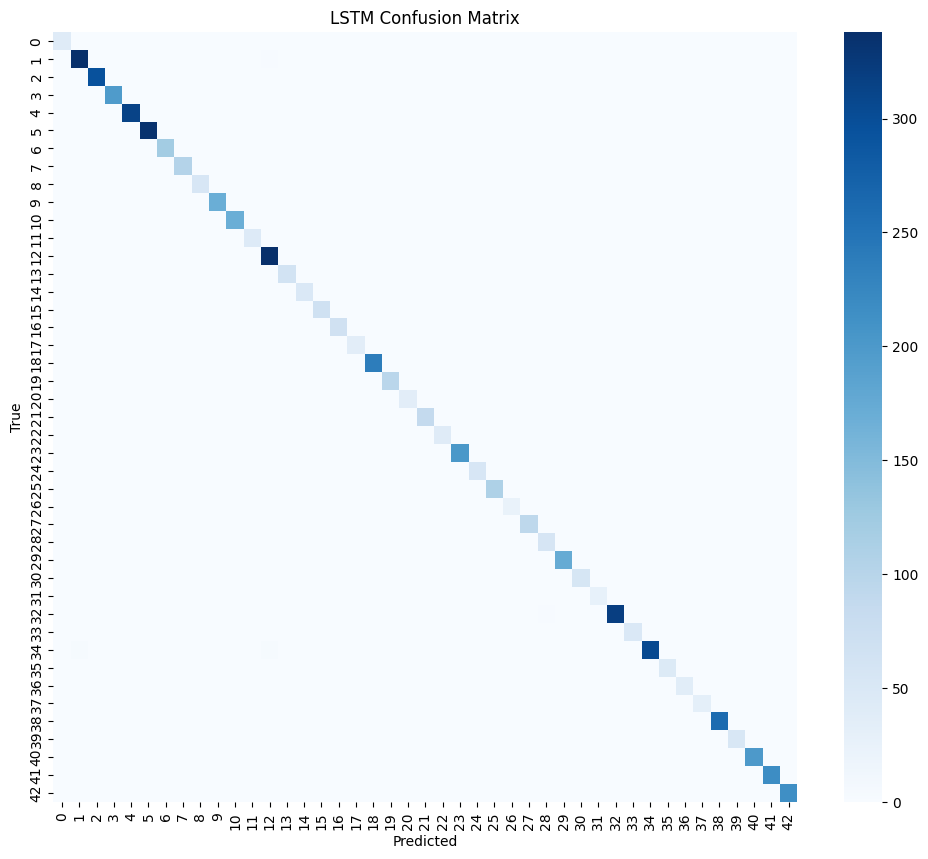

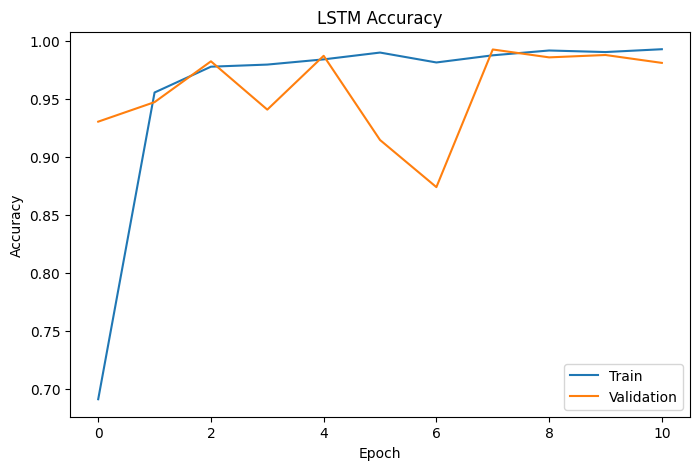

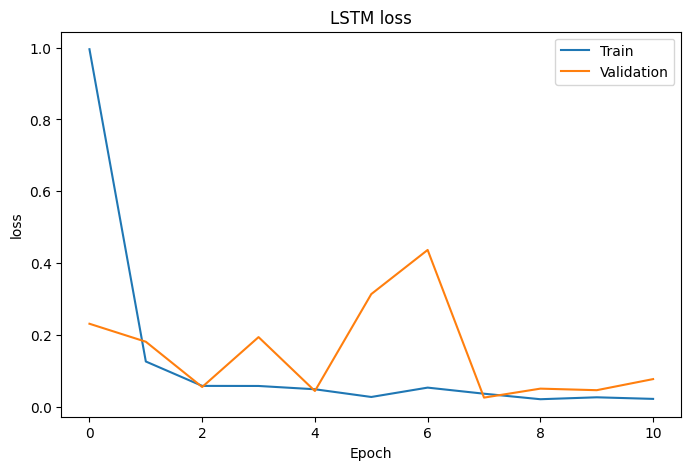

In [ ]:
train(lstm_model, "LSTM")


### **FINAL COMPARISON TABLE**


FINAL RESULTS

            Accuracy      Loss  Training Time
LSTM        0.993701  0.025469    1115.069488
Simple RNN  0.978720  0.085395     913.432851
GRU         0.900409  0.321987     329.037522


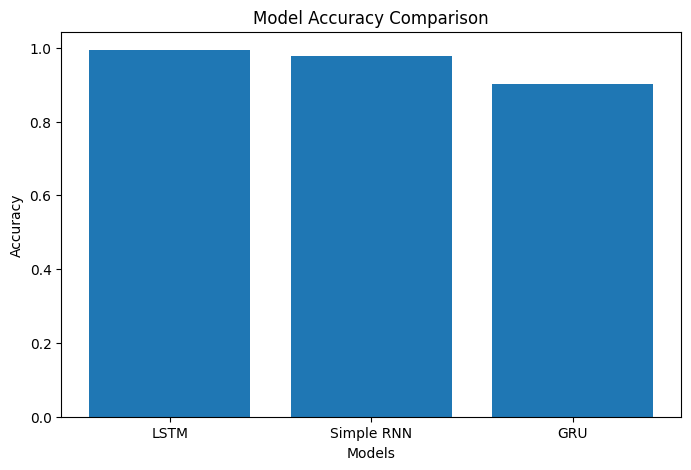

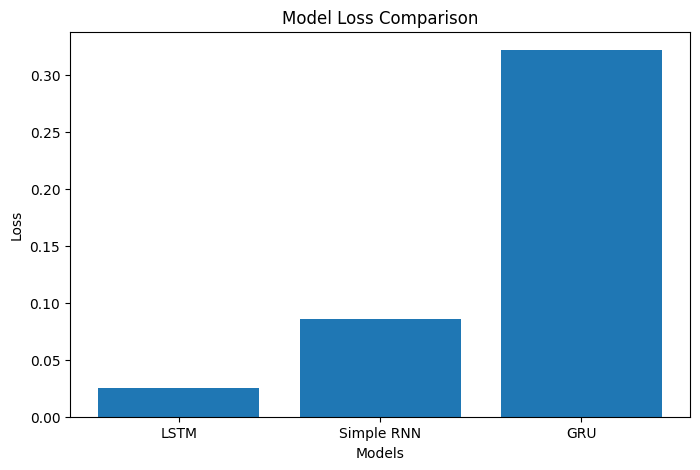

In [ ]:
results_df = pd.DataFrame(results).T

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
)

print("\n========================")
print("FINAL RESULTS")
print("========================\n")
print(results_df)


plt.figure(figsize=(8, 5))
plt.bar(results_df.index, results_df['Accuracy'])
plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(results_df.index, results_df['Loss'])
plt.title("Model Loss Comparison")
plt.xlabel("Models")
plt.ylabel("Loss")
plt.show()

## **Vision Transformer**

In [ ]:
!pip install keras_cv
import keras_cv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 650.7/650.7 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 950.8/950.8 kB 53.8 MB/s eta 0:00:00


In [16]:
IMG_SIZE = (224,224)
def resize_image(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

train_ds = train_ds.map(resize_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(resize_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.map(resize_image, num_parallel_calls=tf.data.AUTOTUNE)

In [17]:
# Hyperparameters
IMAGE_SIZE    = 224
PATCH_SIZE    = 16         # 224/16 = 14x14 = 196 patches seprate each image as patches
NUM_PATCHES   = (IMAGE_SIZE // PATCH_SIZE) ** 2   # 196
PROJECTION_DIM = 64
NUM_HEADS     = 4
TRANSFORMER_LAYERS = 6
MLP_HEAD_UNITS = [128, 64]
NUM_CLASSES   = 43

#  1. Patch Extraction + Linear Embedding
# Patch Embedding
class PatchEmbedding(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super().__init__()
        self.num_patches = num_patches
        self.projection  = layers.Dense(units=projection_dim) # convert each patch into vector with fixed size
        self.position_embedding = layers.Embedding(
            input_dim=num_patches,
            output_dim=projection_dim
        )

    def call(self, patch):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        encoded   = self.projection(patch) + self.position_embedding(positions)
        return encoded

# ── 2. Transformer Encoder Block ────────────────────────────
def transformer_block(x, num_heads, projection_dim, dropout=0.1):
    # Layer Norm 1
    x1 = layers.LayerNormalization(epsilon=1e-6)(x)
    # Multi-Head Self Attention
    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=projection_dim // num_heads,
        dropout=dropout
    )(x1, x1)
    # Skip connection 1
    x2 = layers.Add()([attention_output, x])
    # Layer Norm 2
    x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
    # MLP (Feed-Forward)
    x3 = layers.Dense(projection_dim * 2, activation='gelu')(x3)
    x3 = layers.Dropout(dropout)(x3)
    x3 = layers.Dense(projection_dim)(x3)
    x3 = layers.Dropout(dropout)(x3)
    # Skip connection 2
    return layers.Add()([x3, x2])

def build_vit():
    inputs = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Extract patches: reshape (224,224,3) → (196, 16*16*3=768)
    # Use a Lambda to do the patch extraction cleanly
    patches = layers.Lambda(
        lambda img: tf.reshape(
            tf.image.extract_patches(
                images=img,
                sizes=[1, PATCH_SIZE, PATCH_SIZE, 1],
                strides=[1, PATCH_SIZE, PATCH_SIZE, 1],
                rates=[1, 1, 1, 1],
                padding='VALID'
            ),
            (-1, NUM_PATCHES, PATCH_SIZE * PATCH_SIZE * 3)
        )
    )(inputs)

    # Patch embedding + positional encoding
    encoded = PatchEmbedding(NUM_PATCHES, PROJECTION_DIM)(patches)

    # Transformer encoder blocks
    for _ in range(TRANSFORMER_LAYERS):
        encoded = transformer_block(encoded, NUM_HEADS, PROJECTION_DIM)

    # Global average pooling over patches
    representation = layers.LayerNormalization(epsilon=1e-6)(encoded)
    representation = layers.GlobalAveragePooling1D()(representation)
    representation = layers.Dropout(0.3)(representation)

    # MLP classification head
    for units in MLP_HEAD_UNITS:
        representation = layers.Dense(units, activation='gelu')(representation)
        representation = layers.Dropout(0.2)(representation)

    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(representation)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# ── 4. Build + Train ─────────────────────────────────────────
vit_model = build_vit()
vit_model.summary()

history = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_3 (Lambda)   │ (None, 196, 768)  │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding_3   │ (None, 196, 64)   │     61,760 │ lambda_3[0][0]    │
│ (PatchEmbedding)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ patch_embedding_… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_36 (Add)        │ (None, 196, 64)   │          0 │ multi_head_atten… │
│                     │                   │            │ patch_embedding_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_36[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_49 (Dense)    │ (None, 196, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_64          │ (None, 196, 128)  │          0 │ dense_49[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_50 (Dense)    │ (None, 196, 64)   │      8,256 │ dropout_64[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_65          │ (None, 196, 64)   │          0 │ dense_50[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_37 (Add)        │ (None, 196, 64)   │          0 │ dropout_65[0][0], │
│                     │                   │            │ add_36[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_37[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_38 (Add)        │ (None, 196, 64)   │          0 │ multi_head_atten… │
│                     │                   │            │ add_37[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_38[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_51 (Dense)    │ (None, 196, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_67          │ (None, 196, 128)  │          0 │ dense_51[0][0]    │
│ (Dropout)           │                   │            │                 

 Total params: 282,091 (1.08 MB)

 Trainable params: 282,091 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
858/858 ━━━━━━━━━━━━━━━━━━━━ 106s 76ms/step - accuracy: 0.1030 - loss: 3.3078 - val_accuracy: 0.1855 - val_loss: 2.9347
Epoch 2/40
858/858 ━━━━━━━━━━━━━━━━━━━━ 41s 47ms/step - accuracy: 0.1875 - loss: 2.7746 - val_accuracy: 0.2425 - val_loss: 2.4305
Epoch 3/40
858/858 ━━━━━━━━━━━━━━━━━━━━ 41s 47ms/step - accuracy: 0.2766 - loss: 2.2691 - val_accuracy: 0.3266 - val_loss: 2.0682
Epoch 4/40
858/858 ━━━━━━━━━━━━━━━━━━━━ 40s 46ms/step - accuracy: 0.3543 - loss: 1.9692 - val_accuracy: 0.4144 - val_loss: 1.7229
Epoch 5/40
858/858 ━━━━━━━━━━━━━━━━━━━━ 40s 46ms/step - accuracy: 0.4236 - loss: 1.7452 - val_accuracy: 0.5008 - val_loss: 1.4756
Epoch 6/40
858/858 ━━━━━━━━━━━━━━━━━━━━ 41s 47ms/step - accuracy: 0.4976 - loss: 1.5053 - val_accuracy: 0.5995 - val_loss: 1.1887
Epoch 7/40
858/858 ━━━━━━━━━━━━━━━━━━━━ 41s 47ms/step - accuracy: 0.5678 - loss: 1.2817 - val_accuracy: 0.6439 - val_loss: 1.0430
Epoch 8/40
858/858 ━━━━━━━━━━━━━━━━━━━━ 41s 47ms/step - accuracy: 0.6290 - loss: 1.0955 -